# Code

In [1]:
import os
from pathlib import Path
import matplotlib.pyplot as plt
from collections import Counter
import numpy as np
import pandas as pd
import json
import math
import time
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

## DataSet for the Problem

In [2]:
class MiDataset(Dataset):
    """ Dataset for the problem """

    # Vocabulary: pad, digits, operators, parenthesis
    VOCAB = { c:i for i,c in enumerate("@0123456789+-()") }

    def __init__(self, df: pd.DataFrame, nom: str, size_aug: int = 0,
                 col_input: str = "expression", col_target: str = "value",
                 device: str = "cuda"):
        """ Creates a dataset from the data in a dataframe, adding (if size_aug > 0)
            new entries created by augmentation on top of existing entries.
            Input and target tensors are created directly and sent to the device.
        """
        self.df = df
        self.nom = nom
        self.device = device

        # Augmentation
        for i in torch.randperm(len(df))[:size_aug]:
            self.augment(i.item())

        # Precalculate tensors to send to the network and calculate metrics
        inputs = list(df[col_input])
        targets = list(df[col_target])
        self.max_len = max(map(len,inputs))

        tokens = [self.expr2tok(ex) for ex in inputs]
        self.n_inputs = len(tokens)
        self.t_inputs = torch.tensor(tokens, dtype=torch.long).to(device)
        self.t_targets = torch.tensor(targets, dtype=torch.float).to(device)

    def __len__(self):
        return self.n_inputs

    def __getitem__(self, idx):
        return (self.t_inputs[idx], self.t_targets[idx])

    def augment(self, i):
        """ Add to the dataframe a new expression obtained by adding
            +/- digit terms to the i-th expression of the original dataframe
        """
        ser = self.df.iloc[i].copy()
        expr = ser['expression']
        targ = ser['value']
        # Number of terms to add to the expression. Care is taken to ensure
        # that the expression does not exceed a length of 21
        n = random.randint(0, (21-len(expr))//2)
        if n == 0:
            return
        m = 0
        for _ in range(n):
            x = random.randint(-9,9)  # New digit to add
            if abs(targ+x) >= 100:    # Limit [-99..99] of target
                break
            expr += f"{x:+}"
            targ += x
            m += 1
        ser['id'] = f"augment-{i:05d}"
        ser['expression'] = expr
        ser['value'] = targ
        ser['length'] = len(expr)
        ser['operator_count'] += m
        ser['depth'] += m
        # Add entry to dataframe
        self.df.loc[len(self.df)] = ser

    def vocab_size(self):
        return len(self.VOCAB)

    def get_vocab(self):
        return list(self.VOCAB)  # keys of VOCAB dictionary

    def expr2tok(self, expr):
        # Tokenize and padding
        tokens = [self.VOCAB.get(c, 0) for c in expr][:self.max_len]
        padding = [0] * (self.max_len - len(tokens))
        return tokens + padding

    def tokenize(self, expr):
        """ It is used for isolated predictions only """
        return torch.tensor(self.expr2tok(expr), dtype=torch.long).to(self.device)

    def metrics(self, model: nn.Module):
        """ Calculate the metrics of the model applied to this entire dataset """
        model.eval()
        with torch.no_grad():
            preds = model(self.t_inputs)  # Predictions (float)
            preds_rnd = preds.round()     # Predictions (rounded)
            # Exact-match accuracy
            match = (preds_rnd == self.t_targets).float().mean().item()
            mae = (preds - self.t_targets).abs().mean().item()
            mse = ((preds - self.t_targets)**2).mean().item()
            rmse = math.sqrt(mse)
        return { 'Exact-Match Accuracy': match, 'MAE': mae, 'MSE': mse, 'RMSE': rmse }

    def loss(self, model, floss):
        """ Calculate the loss function over the entire dataset """
        model.eval()
        with torch.no_grad():
            preds = model(self.t_inputs)
            err = floss(preds, self.t_targets)
        return err.item()

    def add_predictions(self, model):
        """ Add (or update) columns with predictions and errors to the Dataframe """
        model.eval()
        with torch.no_grad():
            preds = model(self.t_inputs)
            preds_rnd = preds.round()
            errs = preds - self.t_targets
            self.df['preds'] = preds.cpu().detach().numpy()
            self.df['preds_rnd'] = preds_rnd.cpu().detach().numpy().astype(np.int_)
            self.df['errs'] = errs.cpu().detach().numpy()

## LSTM Model

In [3]:
class LSTM_Model(nn.Module):

    def __init__(self, vocab_size=15, embed_dim=32, hidden_dim=128, num_layers=1, dropout=0.1, bidir=True):
        super().__init__()

        # Hyperparameters (for visualization)
        self.hypernom = ['Type', 'Embed', 'Hidden', 'Layers', 'BiDir']
        self.hyperpar = ['LSTM', embed_dim, hidden_dim, num_layers, bidir]

        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)

        self.lstm = nn.LSTM(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=bidir,
            dropout=dropout if num_layers > 1 else 0
        )

        # Attention pooling over the hidden states
        self.attention = nn.Sequential(
            nn.Linear(hidden_dim * (2 if bidir else 1), 1),
            nn.Softmax(dim=1)
        )

        self.output_head = nn.Sequential(
            nn.Linear(hidden_dim * (2 if bidir else 1), hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, inputs: torch.Tensor):
        # inputs: (batch, seq_len)
        embeds = self.embedding(inputs)  # (batch, seq_len, embed_dim)

        lstm_out, _ = self.lstm(embeds)  # (batch, seq_len, hidden_dim * 2)

        # Attention pooling (enmascarando padding)
        attention_mask = (inputs > 0).float().unsqueeze(-1)  # (batch, seq_len, 1)

        attn_weights = self.attention(lstm_out)  # (batch, seq_len, 1)
        attn_weights = attn_weights * attention_mask
        attn_weights = attn_weights / (attn_weights.sum(dim=1, keepdim=True) + 1e-8)

        pooled = (lstm_out * attn_weights).sum(dim=1)  # (batch, hidden_dim * 2)

        output = self.output_head(pooled).squeeze(-1)  # (batch,)
        return output

## Transformer Model

In [4]:
class SinusoidalPositionalEncoding(nn.Module):
    """ Sinusoidal positional encoding (Vaswani et al., 2017).
        Uses a large buffer (128 positions) so the model can handle sequences
        longer than those seen during training.
    """
    def __init__(self, d_model, max_len=128, dropout=0.1):
        super().__init__()
        self.dropout = nn.Dropout(dropout)

        # Compute PE table: [max_len, d_model]
        pe       = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len).unsqueeze(1).float()
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0)  # [1, max_len, d_model]

        # Register as buffer (saved with model but not a parameter)
        self.register_buffer('pe', pe)

    def forward(self, x):
        # x: [batch, seq_len, d_model]
        x = x + self.pe[:, :x.size(1)]
        return self.dropout(x)


class Transformer_Model(nn.Module):
    """ Transformer encoder
    """
    def __init__(self, vocab_size=15, d_model=128, nhead=4,
                 num_layers=4, dim_feedforward=256, dropout=0.1, max_len=128):
        super().__init__()

        # Hyperparameters (for visualization)
        self.hypernom = ['Type', 'Embed', 'Heads', 'Layers', 'FeedForward']
        self.hyperpar = ['Transformer', d_model, nhead, num_layers, dim_feedforward]

        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=0)
        self.pos_enc   = SinusoidalPositionalEncoding(d_model, max_len, dropout)

        # Stack of Transformer encoder layers
        encoder_layer = nn.TransformerEncoderLayer(
            d_model         = d_model,
            nhead           = nhead,
            dim_feedforward = dim_feedforward,
            dropout         = dropout,
            batch_first     = True,
            norm_first      = True    # Pre-LN: more stable training
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

        # Prediction head
        self.fc = nn.Sequential(
            nn.Linear(d_model, d_model),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_model, 1)
        )

    def forward(self, x):
        # x: [batch, seq_len]

        # Create padding mask: True = ignore this position
        padding_mask = (x == 0)                   # [batch, seq_len]

        emb = self.pos_enc(self.embedding(x))     # [batch, seq_len, d_model]
        out = self.transformer(emb, src_key_padding_mask=padding_mask)  # [batch, seq_len, d_model]

        # Pooling over real (non-padded) tokens
        real_mask = ~padding_mask                 # [batch, seq_len] — True = real token
        # Mean Pooling
        out_masked = out * real_mask.unsqueeze(-1).float()
        lengths    = real_mask.sum(dim=1, keepdim=True).float().clamp(min=1)
        pooled     = out_masked.sum(dim=1) / lengths   # [batch, d_model]
        # Max Pooling
        # out_masked = out.masked_fill(padding_mask.unsqueeze(-1), float('-inf'))
        # pooled = out_masked.max(dim=1)[0]

        return self.fc(pooled).squeeze(-1)         # [batch]

## Trainer

In [5]:
class Trainer:
    """ Stores the model and his training history """
    def __init__(self, model: nn.Module):
        self.model = model
        self.metrics = []  # Training metrics
        # Loss function
        # self.floss = nn.MSELoss()
        self.floss = nn.SmoothL1Loss()

    def predict(self, expr: str):
        """ Obtain an individual prediction (you have to do a microbatch of
            1 element, the unsqueeze(0))
            The model has had to be trained.
        """
        self.model.eval()
        with torch.no_grad():
            pred = self.model(self.ds.tokenize(expr).unsqueeze(0)).item()
        return round(pred)

    def train(self, ds_train, ds_valid, epochs: int = 50, lr: float = 1e-3,
              batch_size: int = 32, weight_decay: float = 0.01, show_epoch=True, preciso=False, warmup=False):
        """ Train the model
            - show_epoch: print loss metrics for each epoch
            - preciso: We found that the loss function for the training model is
              distorted when gradient calculation is enabled. If `preciso` is True,
              the calculation is performed outside the training loop (taking longer).
            - warmup: This option is intended for Transformers-based models,
              for which the scheduler must have an initial warm-up period..
        """
        self.ds = ds_train  # To tokenize values ​​in predict
        dl_train = DataLoader(ds_train, batch_size=batch_size, shuffle=True)
        dl_valid = DataLoader(ds_valid, batch_size=batch_size, shuffle=True)
        model = self.model.to(ds_train.device)
        # Optimizer: AdamW
        optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
        if warmup:
          scheduler = torch.optim.lr_scheduler.OneCycleLR(
              optimizer,
              max_lr=1e-3,
              steps_per_epoch=len(dl_train),
              epochs=epochs,
              pct_start=0.1, # 10% epochs warmup
              anneal_strategy='cos'
          )
        else:
          scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

        self.metrics = []
        print(f"Num. Parameters = {sum(p.numel() for p in model.parameters()):,}")
        tpo1 = time.time()

        for epoch in range(epochs):
            # Training
            model.train()  # Model in training mode
            train_loss = 0
            for (inputs, targets) in dl_train:
                # We have a batch
                # Obtain predictions, calculate loss, and update gradients
                optimizer.zero_grad()
                preds = model(inputs)
                loss = self.floss(preds, targets)
                loss.backward()
                # Gradient clipping: Normalize gradients to avoid the problem of "explosive gradients"
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                # Update network weights
                optimizer.step()
                # Accumulate losses across all batches
                train_loss += loss.item()
                if warmup:
                  # This type of scheduler is updated in batches, not epochs.
                  scheduler.step()

            if not warmup:
              scheduler.step()

            # Evaluation
            eval_loss = 0
            model.eval()
            with torch.no_grad():
                for (inputs, targets) in dl_valid:
                    preds = model(inputs)
                    loss = self.floss(preds, targets)
                    eval_loss += loss.item()

            if preciso:
                train_loss = 0
                model.eval()
                with torch.no_grad():
                    for (inputs, targets) in dl_train:
                        preds = model(inputs)
                        loss = self.floss(preds, targets)
                        train_loss += loss.item()

            met = {'tloss': train_loss/len(dl_train),  # len(ld_train) is the number of batches
                   'vloss': eval_loss/len(dl_valid),
                   'lr': optimizer.param_groups[0]['lr']  # actual learning rate
                  }
            self.metrics.append(met)

            # Write the result of the training run
            if show_epoch:
                print(f"Epoch {epoch+1}/{epochs} | {met}")

        tpo2 = time.time()
        print(f"Tiempo total: {tpo2-tpo1:.2f} segs.")
        return tpo2-tpo1

## Utility Functions

In [6]:
def load_jsonl(path):
    return pd.DataFrame([json.loads(lin) for lin in open(path, "r", encoding="utf-8")])

def train_graph(trainer: Trainer, epoch_ini=0):
    """ Shows the graph of the last training session, starting from a certain epoch. """
    fig, ax = plt.subplots(1,1)
    ejex = list(range(epoch_ini+1,len(trainer.metrics)+1))
    ax.plot(ejex,[m['tloss'] for m in trainer.metrics[epoch_ini:]])
    ax.plot(ejex,[m['vloss'] for m in trainer.metrics[epoch_ini:]])
    ax.set_xlabel("epoch")
    ax.set_ylabel(f"{trainer.floss}")
    ax.set_title("Training and validation loss")
    ax.legend(["Train","Valid"])

def model_metrics(model: nn.Module, dss: [MiDataset], return_df: bool = False):
    """ Create a dataframe with the model metrics for each of the datasets """
    mat = [ds.metrics(model) for ds in dss]
    cols = list(mat[0])  # Names of the metrics
    dfm = pd.DataFrame([[ds.nom, *[fil[c] for c in cols]] for (ds,fil) in zip(dss, mat)], columns=['Dataset',*cols])
    if return_df:
        return dfm
    display(dfm.style.format({cols[0]: '{:,.2%}'.format}))

def error_graphs(df, campo):
  fig, (ax1,ax2,ax3) = plt.subplots(1, 3, figsize=(16,5))
  df.groupby(df[campo]).size().reset_index(name='count').plot.bar(ax=ax1, x=campo,y="count")
  ((df['errs'].abs() > 0.5).groupby(df[campo]).mean()).reset_index(name="frec fallos").plot.bar(ax=ax2, x=campo,y="frec fallos")
  (df['errs'].abs().groupby(df[campo]).mean()).reset_index(name="error abs medio").plot.bar(ax=ax3,x=campo,y="error abs medio")


# Initialization and Data Loading

In [7]:
!pip -q install gdown

DATA_DIR = Path("/content/ML_Exam_Project")
DATA_DIR.mkdir(exist_ok=True)

FOLDER_URL = "https://drive.google.com/drive/folders/1f8t9t6jLE6vFpnu7A-xQuhieDlhk48Iw?usp=share_link"

!gdown --folder "$FOLDER_URL" -O "$DATA_DIR"

expected_files = [
    "train.jsonl",
    "validation.jsonl",
    "test_id.jsonl",
    "test_ood.jsonl",
    "test_long.jsonl",
]

for filename in expected_files:
    path = DATA_DIR / filename
    assert path.exists(), f"Missing file: {path}"

print("All dataset files found:")
for filename in expected_files:
    print(" -", DATA_DIR / filename)

# Load the datasets (into dataframes)

df_train = load_jsonl(DATA_DIR / "train.jsonl")
df_valid = load_jsonl(DATA_DIR / "validation.jsonl")
df_test_id = load_jsonl(DATA_DIR / "test_id.jsonl")
df_test_od = load_jsonl(DATA_DIR / "test_ood.jsonl")
df_test_long = load_jsonl(DATA_DIR / "test_long.jsonl")

print("Train:", df_train.shape)
print("Validation:", df_valid.shape)
print("Test ID:", df_test_id.shape)
print("Test OD:", df_test_od.shape)
print("Test Long:", df_test_long.shape)

Retrieving folder contents
Processing file 1uSTcAolrashExIz6RzS7xMTdiZY7xsxF test_id.jsonl
Processing file 1-y5suAJGJK-OgY7yNm9LkiWnFmCV0zj7 test_long.jsonl
Processing file 1Gr1newDY91vYEQjdyzshR5LYSU_VqT17 test_ood.jsonl
Processing file 184ksDE_EtHRYNt2FaP4Qvhw85OA1AAR4 train.jsonl
Processing file 1nRoACGPmX7BT9vlG_65aenEiXDJmNlwj validation.jsonl
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1uSTcAolrashExIz6RzS7xMTdiZY7xsxF
To: /content/ML_Exam_Project/test_id.jsonl
100% 222k/222k [00:00<00:00, 124MB/s]
Downloading...
From: https://drive.google.com/uc?id=1-y5suAJGJK-OgY7yNm9LkiWnFmCV0zj7
To: /content/ML_Exam_Project/test_long.jsonl
100% 182k/182k [00:00<00:00, 66.3MB/s]
Downloading...
From: https://drive.google.com/uc?id=1Gr1newDY91vYEQjdyzshR5LYSU_VqT17
To: /content/ML_Exam_Project/test_ood.jsonl
100% 230k/230k [00:00<00:00, 113MB/s]
Downloading...
From: https://drive.goog

Creating the datasets (here you must set the data augmentation of the training dataset)

In [8]:
print("\nCreating the datasets..")
ds_train = MiDataset(df_train, "Train", device="cuda")
ds_train_aug = MiDataset(df_train, "Train", size_aug=10, device="cuda")
ds_valid = MiDataset(df_valid, "Valid", device="cuda")
ds_test_id = MiDataset(df_test_id, "Test In", device="cuda")
ds_test_od = MiDataset(df_test_od, "Test Out", device="cuda")
ds_test_long = MiDataset(df_test_long, "Test Long", device="cuda")
print("Train with Augmentation:", ds_train_aug.df.shape)
print("Check: Maximum expression length = ",ds_train_aug.df['expression'].str.len().max())
print("Done!")


Creating the datasets..
Train with Augmentation: (12008, 6)
Check: Maximum expression length =  19
Done!


# LSTM-Training

In [9]:
modelLSTM = LSTM_Model(vocab_size=ds_train.vocab_size(), embed_dim=32,
                       hidden_dim=128, num_layers=2, dropout=0.1, bidir=True)
trainerLSTM = Trainer(modelLSTM)
trainerLSTM.train(ds_train, ds_valid, epochs=50, lr=1e-3, batch_size=32,
                  weight_decay=0.01, show_epoch=True, preciso=True, warmup=False)

Num. Parameters = 594,914
Epoch 1/50 | {'tloss': 0.9394085701306661, 'vloss': 0.9577033193338484, 'lr': 0.0009990133642141358}
Epoch 2/50 | {'tloss': 0.32162606783707937, 'vloss': 0.3143108642053983, 'lr': 0.000996057350657239}
Epoch 3/50 | {'tloss': 0.2702009798487027, 'vloss': 0.2744609363495357, 'lr': 0.0009911436253643444}
Epoch 4/50 | {'tloss': 0.2246022660533587, 'vloss': 0.2336110883052387, 'lr': 0.0009842915805643156}
Epoch 5/50 | {'tloss': 0.2472214060028394, 'vloss': 0.25307707559494746, 'lr': 0.0009755282581475769}
Epoch 6/50 | {'tloss': 0.29893020061651865, 'vloss': 0.3145500019429222, 'lr': 0.0009648882429441258}
Epoch 7/50 | {'tloss': 0.14634979029496512, 'vloss': 0.15783184341021947, 'lr': 0.0009524135262330099}
Epoch 8/50 | {'tloss': 0.161905446211497, 'vloss': 0.171495150242533, 'lr': 0.0009381533400219318}
Epoch 9/50 | {'tloss': 0.22835911406079928, 'vloss': 0.23679391472112565, 'lr': 0.0009221639627510075}
Epoch 10/50 | {'tloss': 0.15858186921477319, 'vloss': 0.16960

145.3048610687256

# LSTM-*Evaluation*

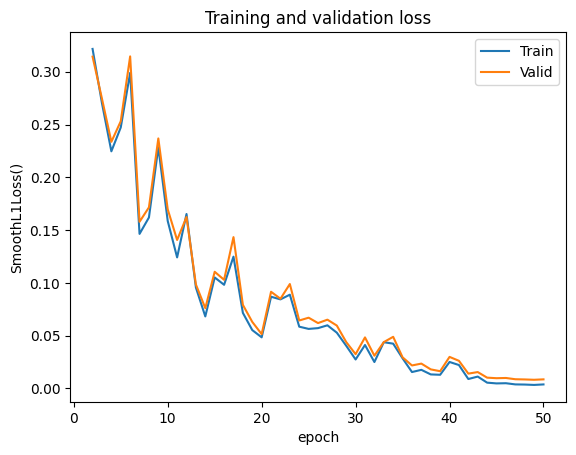

In [10]:
train_graph(trainerLSTM, 1)

In [11]:
model_metrics(modelLSTM, [ds_train, ds_valid, ds_test_id, ds_test_od, ds_test_long])

,Dataset,Exact-Match Accuracy,MAE,MSE,RMSE
0,Train,99.86%,0.057115,0.007589,0.087115
1,Valid,99.05%,0.070744,0.019448,0.139457
2,Test In,99.05%,0.076275,0.027457,0.165702
3,Test Out,90.95%,0.226267,0.207531,0.455555
4,Test Long,60.33%,0.578949,0.866907,0.931078


# Transformer-Training

We only apply augmentation to the Transformers model.

In [12]:
modelTransformer = Transformer_Model(vocab_size=ds_train.vocab_size(), d_model=128,
                                     nhead=4, num_layers=4, dim_feedforward=384, dropout=0.1, max_len=128)
trainerTransformer = Trainer(modelTransformer)
trainerTransformer.train(ds_train_aug, ds_valid, epochs=50, lr=5e-4, batch_size=32,
                         weight_decay=0.1, show_epoch=True, preciso=True, warmup=True)

/tmp/ipykernel_914/4104190525.py:50: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


Num. Parameters = 680,065
Epoch 1/50 | {'tloss': 5.708273356899302, 'vloss': 5.652945862876044, 'lr': 0.00013176620813214039}
Epoch 2/50 | {'tloss': 5.11961164499851, 'vloss': 5.128967659814017, 'lr': 0.0003719771785495981}
Epoch 3/50 | {'tloss': 3.7958630110989224, 'vloss': 3.7688713035886248, 'lr': 0.0006687860366400732}
Epoch 4/50 | {'tloss': 2.8346006832224258, 'vloss': 2.864490404961601, 'lr': 0.00090870518470776}
Epoch 5/50 | {'tloss': 3.9096443076083003, 'vloss': 3.878929062495156, 'lr': 0.0009999999913813888}
Epoch 6/50 | {'tloss': 1.8961180034787097, 'vloss': 1.9237141647036113, 'lr': 0.0009987755454719366}
Epoch 7/50 | {'tloss': 1.6796113542736846, 'vloss': 1.7488614301832894, 'lr': 0.000995121124985487}
Epoch 8/50 | {'tloss': 1.645200713042249, 'vloss': 1.6568003249546839, 'lr': 0.0009890545338913086}
Epoch 9/50 | {'tloss': 1.102010168927781, 'vloss': 1.0701451183311523, 'lr': 0.0009806053280114004}
Epoch 10/50 | {'tloss': 1.012874081810104, 'vloss': 1.0424992924644834, 'lr'

311.37788009643555

# Transformer-Evaluation

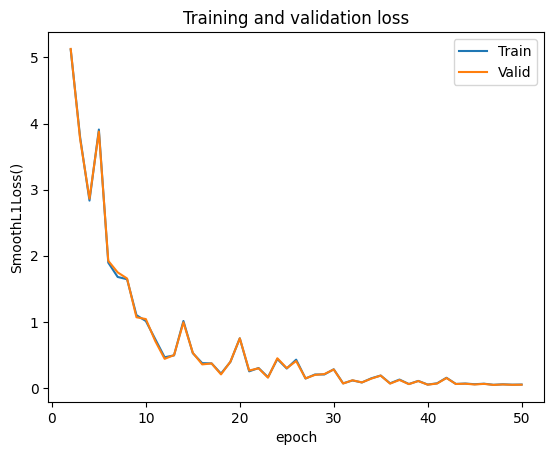

In [13]:
train_graph(trainerTransformer, 1)

In [14]:
model_metrics(modelTransformer, [ds_train, ds_valid, ds_test_id, ds_test_od, ds_test_long])

,Dataset,Exact-Match Accuracy,MAE,MSE,RMSE
0,Train,87.54%,0.230235,0.104890,0.323867
1,Valid,87.15%,0.227495,0.100042,0.316295
2,Test In,87.40%,0.230223,0.101915,0.319241
3,Test Out,72.85%,1.077872,10.839010,3.292265
4,Test Long,28.00%,4.097111,47.376667,6.883071


# Error Analysis

In [15]:
for ds in [ds_train_aug, ds_valid, ds_test_id, ds_test_od, ds_test_long]:
    ds.add_predictions(modelTransformer)

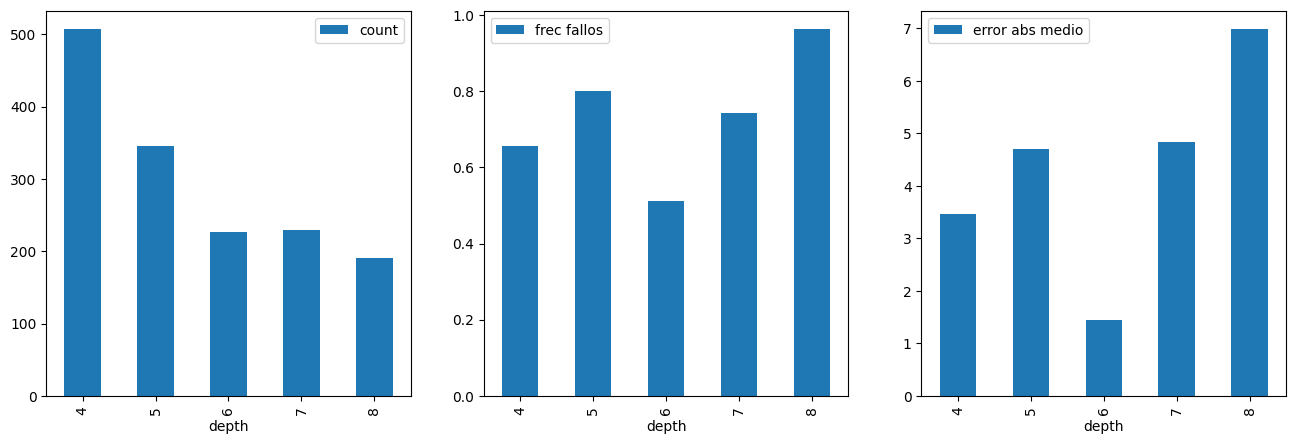

In [16]:
error_graphs(df_test_long, 'depth')

In [17]:
# from torchsummary import summary
# summary(modelTransformer, input_size = (32, 15), dtypes=['torch.IntTensor'], device='cpu' )

In [18]:
# summary(modelLSTM, input_size = (32, 15), dtypes=['torch.IntTensor'], device='cpu' )